# NEOWS
Trata de predecir si el asteroide es peligroso

In [2]:
import json, os, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, auc,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split

from model import HazardNet

try:
    DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    DIR = os.getcwd()
os.chdir(DIR)

In [3]:
df = pd.read_csv("neo.csv")
df = df.loc[df.groupby("name")["miss_km"].idxmin()].reset_index(drop=True)
print("Asteroides únicos: ", len(df), " positive rate: %.3f" % df["hazardous"].mean())

Asteroides únicos:  21522  positive rate: 0.094


In [4]:
num_cols = ["vel_km_h", "vel_km_s", "miss_km", "miss_au", "miss_lunar",
            "epoch_date", "eccentricity", "semi_major_axis", "inclination",
            "ascending_node_longitude", "orbital_period", "perihelion_distance",
            "aphelion_distance", "mean_anomaly", "mean_motion",
            "perihelion_argument", "tisserand_inv", "moid_au",
            "orbit_uncertainty", "obs_used", "data_arc_days"]
for c in num_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

In [4]:
df["diam_mean"] = (df["diam_min_m"] + df["diam_max_m"]) / 2
df["diam_range"] = df["diam_max_m"] - df["diam_min_m"]
df["diam_ratio"] = df["diam_max_m"] / (df["diam_min_m"] + 1e-8)
df["energy_proxy"] = df["diam_mean"].pow(3) * df["vel_km_h"].pow(2)
df["earth_crosser"] = ((df["perihelion_distance"] < 1.0)
                       & (df["aphelion_distance"] > 1.0)).astype(float)

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date_year"] = df["date"].dt.year
df["date_month_sin"] = np.sin(2 * math.pi * df["date"].dt.month / 12)
df["date_month_cos"] = np.cos(2 * math.pi * df["date"].dt.month / 12)

for col, name in [("ascending_node_longitude", "asc_node"),
                  ("perihelion_argument", "peri_arg"),
                  ("mean_anomaly", "mean_anom")]:
    df[f"{name}_sin"] = np.sin(np.deg2rad(df[col]))
    df[f"{name}_cos"] = np.cos(np.deg2rad(df[col]))

orbit_dummies = pd.get_dummies(df["orbit_class_type"], prefix="orbit")
orbit_cols = list(orbit_dummies.columns)
df = pd.concat([df, orbit_dummies], axis=1)

In [5]:
log_features = ["diam_min_m", "diam_max_m", "diam_mean", "diam_range",
                "vel_km_h", "miss_km", "energy_proxy",
                "semi_major_axis", "orbital_period", "perihelion_distance",
                "aphelion_distance", "mean_motion", "obs_used", "data_arc_days"]
raw_features = ["magnitude", "eccentricity", "inclination", "tisserand_inv",
                "moid_au", "orbit_uncertainty", "date_year", "earth_crosser",
                "diam_ratio", "date_month_sin", "date_month_cos",
                "asc_node_sin", "asc_node_cos",
                "peri_arg_sin", "peri_arg_cos",
                "mean_anom_sin", "mean_anom_cos"]
features = log_features + raw_features + orbit_cols
print(f"current: {len(features)}  ({len(log_features)} log, "
      f"{len(raw_features)} raw, {len(orbit_cols)} dummy)")

df2 = df[features].copy()
for c in log_features:
    df2[c] = np.log1p(df2[c])
df2 = df2.fillna(0).values.astype(np.float32)
y = df["hazardous"].values.astype(np.float32)
print("x current", df2.shape, "y", y.shape)

total features current: 35  (14 log1p, 17 crudas, 4 one-hot)
x current (21522, 35) y (21522,)


In [6]:
legacy_features = ["magnitude", "diam_min_m", "diam_max_m", "vel_km_h", "miss_km"]
legacy_log_features = legacy_features[1:]

X2_legacy = df[legacy_features].copy()
for c in legacy_log_features:
    X2_legacy[c] = np.log1p(X2_legacy[c])
X2_legacy = X2_legacy.fillna(0).values.astype(np.float32)
print("x legacy", X2_legacy.shape)

x legacy (21522, 5)


In [8]:
def train_hazard(X2, y, d_in, legacy):
    split = train_test_split(X2, y, test_size=0.2, stratify=y, random_state=67)
    xtr, xval, ytr, yval = map(np.asarray, split)
    mu, sigma = xtr.mean(0), xtr.std(0) + 1e-8
    xtr, xval = (xtr - mu) / sigma, (xval - mu) / sigma

    Xtr = torch.tensor(xtr, dtype=torch.float32)
    Xval = torch.tensor(xval, dtype=torch.float32)

    model = HazardNet.legacy(d_in) if legacy else HazardNet(d_in=d_in)
    print("2 muestras", model(Xtr[:2]).shape)

    targets = torch.tensor(ytr, dtype=torch.float32)
    weights = torch.where(targets == 1, torch.tensor(6.0), torch.tensor(1.0))
    sampler = torch.utils.data.WeightedRandomSampler(
        weights, num_samples=len(targets), replacement=True
    )
    dl = torch.utils.data.DataLoader(
        list(zip(Xtr, targets)), batch_size=64, sampler=sampler
    )
    opt = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.BCELoss()

    epochs, patience, best_loss, wait = 200, 10, float("inf"), 0
    best_state = None

    for epoch in range(epochs):
        model.train()
        for xb, yb in dl:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb.view(-1,1))
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            vloss = loss_fn(model(Xval), torch.tensor(yval, dtype=torch.float32).view(-1,1)).item()
            if vloss < best_loss:
                best_loss, wait = vloss, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait == patience:
                    print(f"ES {epoch}, {best_loss:.4f}")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)

    with torch.no_grad():
        p = model(Xval).flatten()
    y_pred = (p > 0.5).int().numpy()
    return dict(model=model, mu=mu, sigma=sigma, p=p.numpy(), yval=yval, y_pred=y_pred)

In [10]:
results = {}
results["legacy"]  = train_hazard(X2_legacy, y, X2_legacy.shape[1], legacy=True)
results["current"] = train_hazard(df2, y, df2.shape[1], legacy=False)

2 muestras torch.Size([2, 1])
ES 13, 0.2490
2 muestras torch.Size([2, 1])
ES 29, 0.0218


In [12]:
rows = []
for name, r in results.items():
    yv, p, yp = r["yval"], r["p"], r["y_pred"]
    tn, fp, fn, tp = confusion_matrix(yv, yp).ravel()
    rows.append({
        "modelo": name,
        "n": 5 if name == "legacy" else 35,
        "accuracy": round(accuracy_score(yv, yp), 4),
        "AUC": round(roc_auc_score(yv, p), 4),
        "precision": round(precision_score(yv, yp), 4),
        "recall": round(recall_score(yv, yp), 4),
        "F1": round(f1_score(yv, yp), 4),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
mtab = pd.DataFrame(rows).set_index("modelo")
print(mtab.to_string())

          n  accuracy     AUC  precision  recall      F1    TN   FP  FN   TP
modelo                                                                      
legacy    5    0.8825  0.9403     0.4357  0.8660  0.5797  3450  452  54  349
current  35    0.9921  0.9992     0.9489  0.9677  0.9582  3881   21  13  390


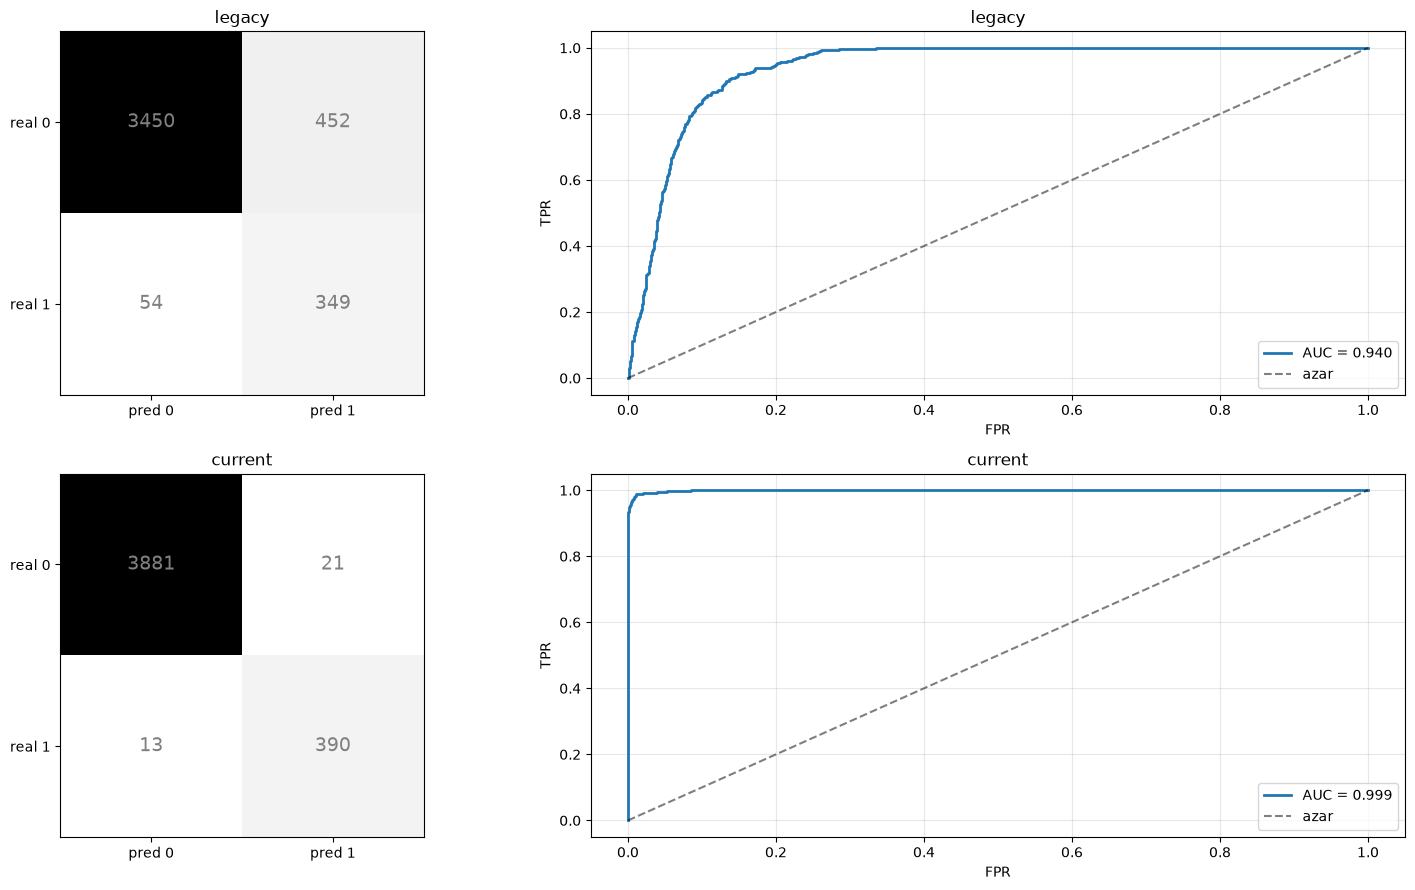


legacy: Muestra real vs predicho
 real  P(haz)  pred
  0.0   0.642     1
  0.0   0.001     0
  0.0   0.531     1
  0.0   0.000     0
  1.0   0.916     1
  0.0   0.027     0
  0.0   0.011     0
  0.0   0.000     0
  0.0   0.000     0
  1.0   0.573     1

current: Muestra real vs predicho
 real  P(haz)  pred
  0.0   0.000     0
  0.0   0.000     0
  0.0   0.000     0
  0.0   0.000     0
  1.0   1.000     1
  0.0   0.000     0
  0.0   0.000     0
  0.0   0.000     0
  0.0   0.000     0
  1.0   0.616     1


In [24]:
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

for row, (name, r) in enumerate(results.items()):
    yv, p, yp = r["yval"], r["p"], r["y_pred"]

    cm = confusion_matrix(yv, yp)
    ax = axes[row, 0]
    im = ax.imshow(cm, cmap="Grays")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred 0", "pred 1"])
    ax.set_yticklabels(["real 0", "real 1"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    fontsize=14, color="gray")
    ax.set_title(name)

    fpr, tpr, _ = roc_curve(yv, p)
    ax = axes[row, 1]
    ax.plot(fpr, tpr, lw=2, label=f"AUC = {auc(fpr, tpr):.3f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="azar")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.set_title(name)
    ax.grid(alpha=0.3); ax.legend()

plt.tight_layout()
plt.show()

for name, r in results.items():
    tab = pd.DataFrame({"real": r["yval"], "P(haz)": r["p"].round(3), "pred": r["y_pred"]})
    print(f"\n{name}: Muestra real vs predicho")
    print(tab.sample(10, random_state=0).to_string(index=False))

In [28]:
r = results["current"]
torch.save(r["model"].state_dict(), "hazard_model_full.pt")
json.dump({
    "features": features,
    "log_features": log_features,
    "mu": r["mu"].tolist(),
    "sigma": r["sigma"].tolist(),
    "min": df2.min(0).tolist(),
    "max": df2.max(0).tolist(),
}, open("stats_full.json", "w"), indent=2)
print("hazard_model_full.pt y stats_full.json generados")

r = results["legacy"]
torch.save(r["model"].state_dict(), "hazard_model.pt")
json.dump({
    "features": legacy_features,
    "log_features": legacy_log_features,
    "mu": r["mu"].tolist(),
    "sigma": r["sigma"].tolist(),
    "min": X2_legacy.min(0).tolist(),
    "max": X2_legacy.max(0).tolist(),
}, open("stats.json", "w"), indent=2)
print("hazard_model.pt y stats.json generados")

hazard_model_full.pt y stats_full.json generados
hazard_model.pt y stats.json generados


In [29]:
AU = 149597870.7
np.savez_compressed("game_data.npz",
    X      = df[features].fillna(0).astype(np.float32).values,
    diam_max = df["diam_max_m"].values.astype(np.float32),
    vel      = df["vel_km_h"].values.astype(np.float32),
    mag      = df["magnitude"].values.astype(np.float32),
    miss     = df["miss_km"].values.astype(np.float32),
    truth    = ((df["magnitude"] <= 22.0) &
                (df["miss_km"] <= 0.05 * AU)).values.astype(np.int8),
    label    = df["hazardous"].values.astype(np.int8))
print("game_data.npz generado:", len(df), "asteroides")

game_data.npz generado: 21522 asteroides
